# Lab 6 — Localization: model vs real odometry

Trajectory: digits **9** and **1** (last two digits of the student ID). The same block program
(`trajectory_sim.qrs` / `trajectory_real.qrs`, only `r`, `B` and the log name differ) drives the
digits by its own odometry and logs `x,y,time` (m, m, ms) every 20 ms.

Odometry (professor's form, wheel angles θ in rad, left = E4, right = E3):
`path = (θ_r + θ_l)·r/2`, `φ = (θ_r − θ_l)·r/B`, `x += Δpath·cos φ`, `y += Δpath·sin φ`.

In [1]:
import os
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

try:                                # in Colab: upload both txt files
    from google.colab import files  # file work module
    uploaded = files.upload()       # select BOTH txt files
except ImportError:                 # local Jupyter: files next to the notebook
    pass

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt', delimiter=',', unpack=True)
have_real = os.path.exists('odometry_data_real.txt')
if have_real:
    x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)
print(f'sim:  {len(t_s)} samples, {t_s[-1] / 1000:.1f} s')
if have_real:
    print(f'real: {len(t_r)} samples, {t_r[-1] / 1000:.1f} s')

sim:  1856 samples, 37.1 s
real: 471 samples, 28.3 s


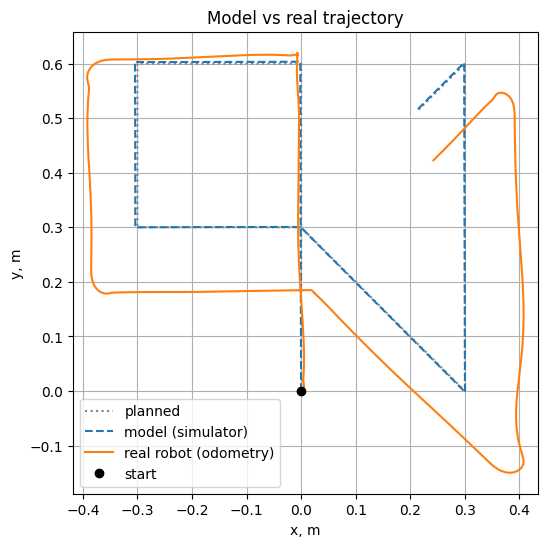

In [2]:
# Planned path (corners of the 9 and the 1), for reference
a, f = 0.30, 0.12
plan = np.array([(0, 0), (0, 2*a), (-a, 2*a), (-a, a), (0, a), (a, 0), (a, 2*a),
                 (a - f / np.sqrt(2), 2*a - f / np.sqrt(2))])

# 1. Trajectories on one plot
plt.figure(figsize=(6, 6))
plt.plot(plan[:, 0], plan[:, 1], ':', color='gray', label='planned')
plt.plot(x_s, y_s, '--', label='model (simulator)')
if have_real:
    plt.plot(x_r, y_r, label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

## Error between model and real

The README's error resamples the simulator onto the real-robot **timestamps**. The simulated robot
drives slower than the real one, so this error mostly measures *when* each robot is somewhere, not
*where* the paths differ. The second plot therefore also compares the two at equal **distance
travelled** (arc length), which isolates the shape error.

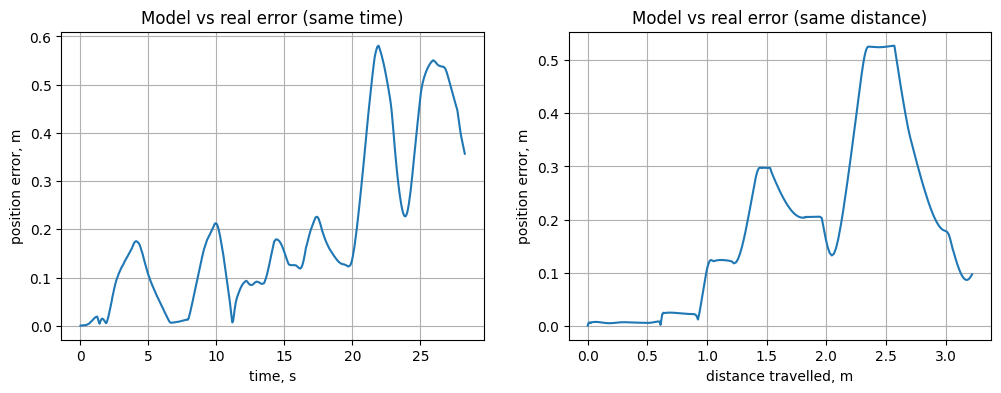

Final odometry error (sim vs real): 0.097 m
Max error, same time:     0.581 m
Max error, same distance: 0.527 m
Path length: sim 2.69 m, real 3.22 m


In [3]:
if have_real:
    # 2a. Error over time (simulator resampled onto the real-robot timestamps), as in the README
    t_s0, t_r0 = t_s - t_s[0], t_r - t_r[0]
    xs_i = np.interp(t_r0, t_s0, x_s)
    ys_i = np.interp(t_r0, t_s0, y_s)
    err = np.hypot(x_r - xs_i, y_r - ys_i)

    # 2b. Error at equal distance travelled
    def arc(x, y):
        return np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])
    s_s, s_r = arc(x_s, y_s), arc(x_r, y_r)
    keep = np.concatenate([[True], np.diff(s_s) > 0])            # drop samples where the robot stood still
    xs_a = np.interp(s_r, s_s[keep], x_s[keep])
    ys_a = np.interp(s_r, s_s[keep], y_s[keep])
    err_s = np.hypot(x_r - xs_a, y_r - ys_a)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(t_r0 / 1000, err)
    ax[0].set_xlabel('time, s'); ax[0].set_ylabel('position error, m'); ax[0].grid(True)
    ax[0].set_title('Model vs real error (same time)')
    ax[1].plot(s_r, err_s)
    ax[1].set_xlabel('distance travelled, m'); ax[1].set_ylabel('position error, m'); ax[1].grid(True)
    ax[1].set_title('Model vs real error (same distance)')
    plt.show()

    print(f'Final odometry error (sim vs real): {np.hypot(x_r[-1] - x_s[-1], y_r[-1] - y_s[-1]):.3f} m')
    print(f'Max error, same time:     {err.max():.3f} m')
    print(f'Max error, same distance: {err_s.max():.3f} m')
    print(f'Path length: sim {s_s[-1]:.2f} m, real {s_r[-1]:.2f} m')
else:
    print('odometry_data_real.txt not found yet - run trajectory_real.qrs on the robot first')

## Measured end point (tape)

Before the run, mark the point between the two wheels and the direction the robot faces.
After the run measure the robot's real final position in that frame: **x** along the start
direction, **y** to the left (m). The robot's odometry believes it is at the last log line.

In [4]:
x_meas, y_meas = 0.19, 0.535  # tape after run 2: 19 cm ahead, 53.5 cm to the left

x_plan, y_plan = plan[-1]
print(f'planned end:          ({x_plan:.3f}, {y_plan:.3f}) m')
print(f'simulator odometry:   ({x_s[-1]:.3f}, {y_s[-1]:.3f}) m')
if have_real:
    print(f'real odometry (log):  ({x_r[-1]:.3f}, {y_r[-1]:.3f}) m')
if have_real and x_meas is not None:
    print(f'measured with tape:   ({x_meas:.3f}, {y_meas:.3f}) m')
    print(f'odometry error (log vs tape): {np.hypot(x_r[-1] - x_meas, y_r[-1] - y_meas):.3f} m')

planned end:          (0.215, 0.515) m
simulator odometry:   (0.212, 0.515) m
real odometry (log):  (0.242, 0.423) m
measured with tape:   (0.190, 0.535) m
odometry error (log vs tape): 0.124 m


## Discussion

The real trajectory leaves the model at every corner. Each leg of the 9 and the 1 comes out 5–14 cm too long and the corners are rounded, so the real path is 3.2 m against 2.7 m in the simulator. The overshoot is in the robot's own log, so it comes from the robot's dynamics and not from bad odometry. On the robot the control loop ran every 59 ms instead of 20 ms, and the motors need about 0.16 s to slow down (T_m from Lab 5). After "distance reached" the robot coasts into the next turn. The simulator's motors have no lag and no dead zone. The tape puts the real end at (0.19, 0.535) m, while the odometry believes it is at (0.242, 0.423) m: 0.12 m off after 3.2 m of driving (about 4 %), mostly sideways. That points to heading error, the lecture's "heading error dominates": wheel slip in the in-place turns (the log shows the robot stalling near the dead zone at about 5 s and 19 s) and the unmeasured nominal r and B. The robot does not know it is wrong. Its log ends at a confident pose and only the tape reveals the difference, and two identical runs ended 10 cm apart in the robot's own belief.